<a href="https://colab.research.google.com/github/pazolka/ai-climate-workshop-dhaka/blob/main/template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Anomaly detection

Anomalies appear for various reasons. In environmental datasets, they can be a sign of a sensor error, a human mistake, or a genuine extreme event. How can we flag these physically rare or unrealistic outliers? 


In [46]:
# importing important libraries we need
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

### 1.1. Isolated outliers


Let's look into an example of a groundwater level time-series from the BWDB monitoring network.

Size of the dataset: (708, 13)
            MY050  DH071  JA001  MY055  RJ007  BO034  SY105  DH088  RJ105  \
Date                                                                        
1961-01-01    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
1961-02-01    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   

            KT010  CT038  BA016  DI074  
Date                                    
1961-01-01    NaN    NaN    NaN    NaN  
1961-02-01    NaN    NaN    NaN    NaN  


<Axes: xlabel='Date'>

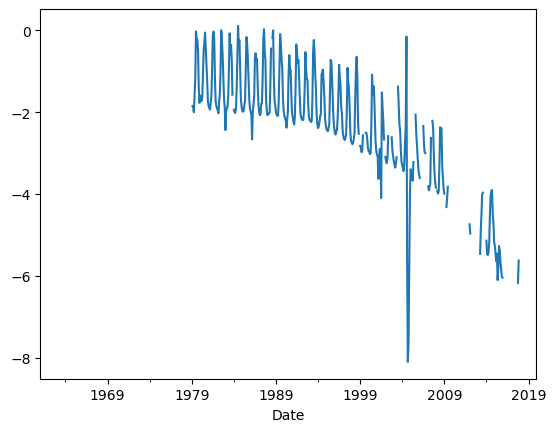

In [47]:
# reading the BWDB groundwater level data from a csv file
gwl_data = pd.read_csv('../data/point_observations/BWDB_gwl_ts_monthly.csv', parse_dates=True, index_col='Date')

print("Size of the dataset:", gwl_data.shape)
# first few rows of the dataset
print(gwl_data.head(2))

# an example time series data with an outlier
id = 'SY105' # RJ007 SY105
gwl_data[id].plot()

The most straight-forward way is to use statistical and distribution-based methods, such as z-score (for normally distributed data), median or interquartile range (IQR) - based threshold. 

However, these are not well suitable for time series data with trend, like our example time series. As we can see below, IQR flags multiple valid observations.

Outliers found:
[-5.706, -8.1025, -7.6425, -5.798, -5.462, -5.465, -5.49, -5.42, -5.45, -5.642, -5.455, -6.1025, -5.792, -5.372, -5.655, -5.845, -6.016, -6.0425, -6.1275, -6.174, -5.62]


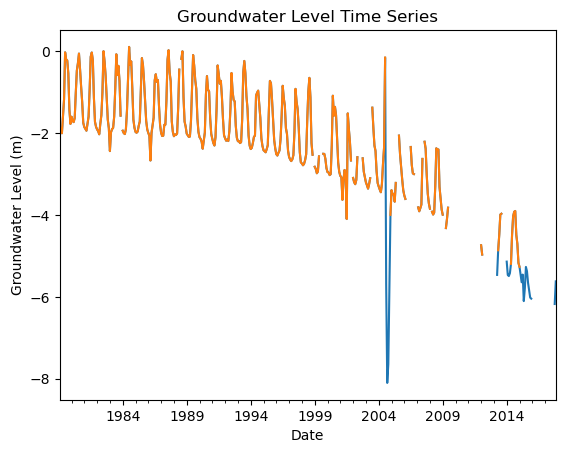

In [48]:
first_valid_index, last_valid_index = gwl_data[id].first_valid_index(), gwl_data[id].last_valid_index()
well = gwl_data[id].loc[first_valid_index:last_valid_index].copy()

# Step 1: Calculate Q1, Q3, and IQR
q1 = well.quantile(0.25)
q3 = well.quantile(0.75)
iqr = q3 - q1

# Step 2: Define thresholds
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

# Step 3: Filter outliers
outliers = well[(well < lower_fence) | (well > upper_fence)]
clean_data = well[(well >= lower_fence) & (well <= upper_fence)]

# Plot the original data and the cleaned data
well.plot()
clean_data.resample("MS").first().plot()
plt.gca().set(title='Groundwater Level Time Series', xlabel='Date', ylabel='Groundwater Level (m)')

print("Outliers found:")
print(outliers.tolist())


Statistical methods with global thresholds like IQR and standard z-score break on time-series data. These methods assume that data points are independent and identically distributed, but time-series data is highly dependent on past points (autocorrelation). A presence of trend and seasonality in many environmental observations needs special considerations.

Season-Trend decomposition (STL) is a commonly used tool to transform time-series data. It separates a sequence of measurements into a long-term trend, a repeating seasonal pattern (like the yearly monsoon cycle), and remainder. Z-score, median or IQR can be applied on STL's remainder for a more robust outlier detection.

STL requires data with no gaps, but our time-series has missing values. For this reason, we will adopt 3-step approach. First, we find the worst outliers with a median threshold based on 12-month rolling window, clean them and temporarly fill the gaps with a simple interpolation method, and then run the final STL decomposition with z-score .

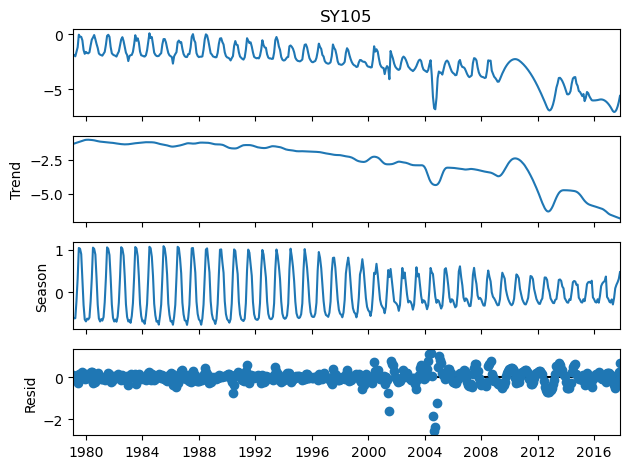

In [49]:
first_valid_index, last_valid_index = gwl_data[id].first_valid_index(), gwl_data[id].last_valid_index()
well = gwl_data[id][first_valid_index:last_valid_index].copy()

# Step 1: find worst outliers using median and median absolute deviation (MAD)
# Calculate rolling baseline using median
rolling_median = well.rolling(window=12, center=True, min_periods=1).median()
rolling_mad = (well - rolling_median).abs().rolling(window=12, center=True, min_periods=1).median()

# Define a threshold (typically 3 to 5 times the MAD)
lower_bound = rolling_median - (4 * rolling_mad)
upper_bound = rolling_median + (4 * rolling_mad)

# Step 2: flag outliers and set them to NaN (not defined)
is_outlier = (well < lower_bound) | (well > upper_bound)
working = well.copy()
working.loc[is_outlier] = np.nan

# Fill NaNs using a simple polynomial interpolation method
well_interpolated = working.interpolate(method='polynomial', order=2)

# Step 3: Use STL decomposition to separate trend, seasonal, and residual components
from statsmodels.tsa.seasonal import STL

stl = STL(well_interpolated, period=12, seasonal=13)
res = stl.fit()
fig = res.plot()

# Find anomalies using z-scores of residuals
residuals = res.resid
z_scores = (residuals - residuals.mean()) / residuals.std(ddof=0)
threshold = 3
anomalies = z_scores.abs() > threshold

cleaned_data = well.mask(anomalies)


<Axes: xlabel='Date'>

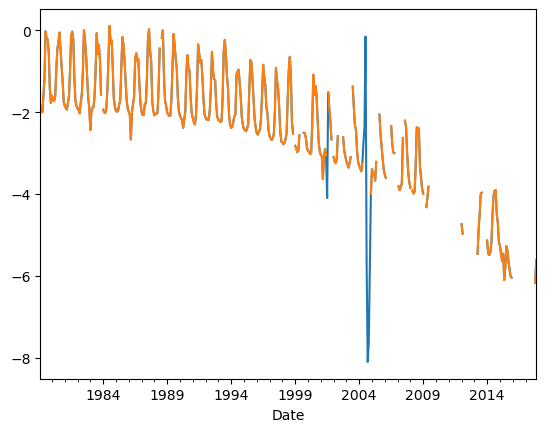

In [50]:
# Plot the original data and anomalies
well.plot()
cleaned_data.plot()

This approach found 3 outliers that seem plausible, but do they represent a response to genuine extreme events or are they caused by sensor or human error? This remains to be assessed by a human expert...

Let's look at a second type of anomalies common in the BWDB groundwater datset.

<Axes: xlabel='Date'>

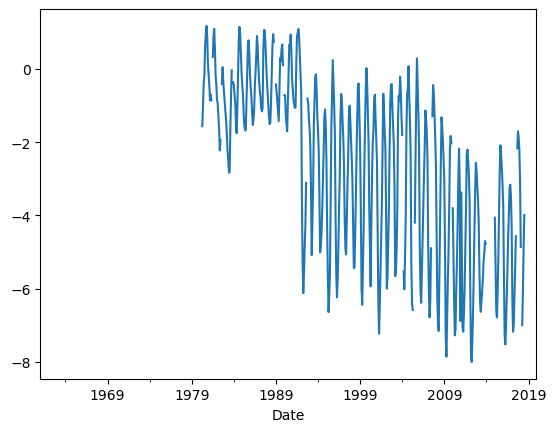

In [57]:
id = 'BO034' # DH071 MY055 RJ105 BO034
gwl_data[id].plot()

##### 1.1.2. Systematic shifts

A sudden change in statistical properties of the time series may indicate change of well, or a shift in the datum system. Such structural shifts can't be easily detected with STL-based analysis.

Here, a suitable approach is changepoint analysis, that helps to identify abtupt structural changes that contaminate the data. We use linearly penalized segmentation (Pelt) algorithm as an example.

In [58]:
first_valid_index, last_valid_index = gwl_data[id].first_valid_index(), gwl_data[id].last_valid_index()
well = gwl_data[id][first_valid_index:last_valid_index].copy()

import ruptures as rpt

# Step 1: Interpolate missing values using polynomial interpolation
well_interpolated = well.copy().interpolate(method='polynomial', order=3)

# Step 2: Apply change point detection using the PELT algorithm
algo = rpt.Pelt(model="rbf").fit(well_interpolated.values)
# the result is a list of indices where change points occur
change_points = algo.predict(pen=30)[:-1]

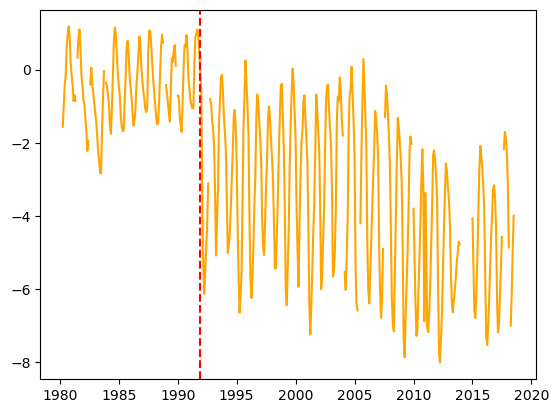

In [59]:
plt.figure()
plt.plot(well, label="TS", color="orange")

for i, brk in enumerate(change_points):
    plt.axvline(well.index[brk], color="red", ls="--",
                label="Breakpoint" if i == 0 else "")

### Summary
Treating anomalous observations and outliers is a crucial pre-processing step for many machine and deep learning models. In our examples, we looked into groundwater level data from BWDB, that is a complex time series dataset. Simple statistical methods presented above are powerful, but need to be combined with expert knowledge to create a robust approach to flag true measurement errors while retaining dynamic, seemingly anomalous groundwater behaviour.

### Bonus: spatiotemporal outlier detection with deep learning

Environmental observations are spatially correlated with their neighbours. Treating time-series individually could miss instances where a sensor stays within its overall historical limits but deviates completely from its peers. Multivariate time series anomaly detection using deep learning, such as TSAD-C, uses spatial correlation between the neighbouring wells and each well's history to flag outliers. Reach out to Anna if you would like to find out more about these models!

isolation forest?